# Análisis Exploratorio De Datos


## Importando Librerias

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.express as px
import warnings

In [2]:
df = pd.read_csv("./data/FraudTrainClean.csv")
warnings.simplefilter("ignore")
df.head()

,trans_num,trans_date,cc_num,merchant,type_purcharse,amount,gender,city,state,city_pop,job,merch_lat,merch_long,fraud,trans_year,trans_month,age,age_groups,name
0,0b242abb623afc578575680df30655b9,2019-01-01,2703186189652095,"Rippin, Kub and Mann",misc_net,4.97,F,Moravian Falls,NC,3495,health and medicine,36.011293,-82.048315,0,2019,january,32,Adult,Jennifer_Banks
1,1f76529f8574734946361c461b024d99,2019-01-01,630423337322,"Heller, Gutmann and Zieme",grocery_pos,107.23,F,Orient,WA,149,education and academia,49.159047,-118.186462,0,2019,january,42,Adult,Stephanie_Gill
2,a1a22d70485983eac12b5b88dad1cf95,2019-01-01,38859492057661,Lind-Buckridge,entertainment,220.11,M,Malad City,ID,4154,environmental science and conservation,43.150704,-112.154481,0,2019,january,58,Adult,Edward_Sanchez
3,6b849c168bdad6f867558c3793159a81,2019-01-01,3534093764340240,"Kutch, Hermiston and Farrell",gas_transport,45.00,M,Boulder,MT,1939,legal and law,47.034331,-112.561071,0,2019,january,53,Adult,Jeremy_White
4,a41d7549acf90789359a9aa5346dcb46,2019-01-01,375534208663984,Keeling-Crist,misc_pos,41.96,M,Doe Hill,VA,99,psychology and social work,38.674999,-78.632459,0,2019,january,34,Adult,Tyler_Garcia


In [3]:
df["trans_date"] = pd.to_datetime(df["trans_date"])

## Análisis Descriptivo Univariado

### Información General

In [5]:
df.shape

(1296675, 19)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 19 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   trans_num       1296675 non-null  object        
 1   trans_date      1296675 non-null  datetime64[ns]
 2   cc_num          1296675 non-null  int64         
 3   merchant        1296675 non-null  object        
 4   type_purcharse  1296675 non-null  object        
 5   amount          1296675 non-null  float64       
 6   gender          1296675 non-null  object        
 7   city            1296675 non-null  object        
 8   state           1296675 non-null  object        
 9   city_pop        1296675 non-null  int64         
 10  job             1296675 non-null  object        
 11  merch_lat       1296675 non-null  float64       
 12  merch_long      1296675 non-null  float64       
 13  fraud           1296675 non-null  int64         
 14  trans_year      12

In [6]:
df.describe()

,trans_date,cc_num,amount,city_pop,merch_lat,merch_long,fraud,trans_year,age
count,1296675,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,2019-10-02 23:29:11.362831872,4.171920e+17,7.035104e+01,8.882444e+04,3.853734e+01,-9.022646e+01,5.788652e-03,2.019287e+03,4.674255e+01
min,2019-01-01 00:00:00,6.041621e+10,1.000000e+00,2.300000e+01,1.902779e+01,-1.666712e+02,0.000000e+00,2.019000e+03,1.500000e+01
25%,2019-06-03 00:00:00,1.800429e+14,9.650000e+00,7.430000e+02,3.473357e+01,-9.689728e+01,0.000000e+00,2.019000e+03,3.300000e+01
50%,2019-10-03 00:00:00,3.521417e+15,4.752000e+01,2.456000e+03,3.936568e+01,-8.743839e+01,0.000000e+00,2.019000e+03,4.500000e+01
75%,2020-01-28 00:00:00,4.642255e+15,8.314000e+01,2.032800e+04,4.195716e+01,-8.023680e+01,0.000000e+00,2.020000e+03,5.800000e+01
max,2020-06-21 00:00:00,4.992346e+18,2.894890e+04,2.906700e+06,6.751027e+01,-6.695090e+01,1.000000e+00,2.020000e+03,9.600000e+01
std,NaN,1.308806e+18,1.603160e+02,3.019564e+05,5.109788e+00,1.377109e+01,7.586269e-02,4.522452e-01,1.737848e+01


### Observaciones:
### . Se cuentan con 1296675 transacciones crediticias y 19 características
### . Se tiene 10 variables de tipo categorico y 9 variables de tipo numerico
### . A simple vista se evidencia una alta variabilidad en los datos

### Variables Numericas

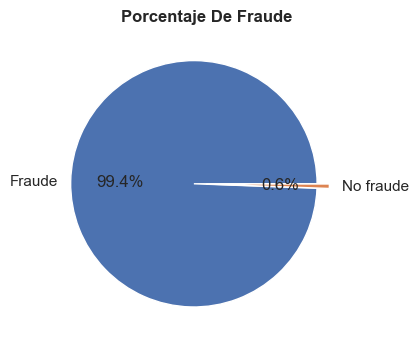

Numero de transacciones no fraudulentas:  1289169
Numero de transacciones fraudulentas:  7506


In [7]:
f = df["fraud"].value_counts()

sns.set_theme(style="dark")
plt.figure(figsize=(4,4))
plt.pie(f, labels=["Fraude","No fraude"], autopct="%1.1f%%",startangle=0, explode=(0.1,0))
plt.title("Porcentaje De Fraude", fontweight="bold")
plt.show()
print("Numero de transacciones no fraudulentas: ", f[0])
print("Numero de transacciones fraudulentas: ", f[1])

## Observaciones:
### . Hay mas transacciones no fraudulentas con un 99.4% del total de datos frente a un 0.6%  fraudulentas
### . La diferencia entre estas dos categorias es muy grande

In [5]:
def agrupar(df, cantidades = []):
    for i in df["amount"]:
        if i <= 4000:
            cantidades.append(1)
        elif 4000 < i <= 8000:
            cantidades.append(2)
        elif 8000 < i <= 12000:
            cantidades.append(3)
        elif 12000 < i <= 16000:
            cantidades.append(4)
        elif 16000 < i <= 20000:
            cantidades.append(5)
        elif 20000 < i <= 24000:
            cantidades.append(6)
        elif 24000 < i <= 26000:
            cantidades.append(7)
        else:
            cantidades.append(8)
    return cantidades
            
df["cat_amount"] = agrupar(df)

In [9]:
print(" Estadisticas descriptivas de los montos por grupos")
df.pivot_table(columns="cat_amount", values= "amount", aggfunc="describe" ).round()

 Estadisticas descriptivas de los montos por grupos


cat_amount,1,2,3,4,5,7,8
25%,10.0,4407.0,8643.0,12788.0,17897.0,25087.0,26976.0
50%,48.0,5138.0,9455.0,14175.0,17897.0,25087.0,27255.0
75%,83.0,6124.0,10665.0,14685.0,17897.0,25087.0,27780.0
count,1296474.0,142.0,37.0,16.0,1.0,1.0,4.0
max,3999.0,7865.0,11961.0,15306.0,17897.0,25087.0,28949.0
mean,69.0,5380.0,9662.0,13815.0,17897.0,25087.0,27501.0
min,1.0,4016.0,8059.0,12025.0,17897.0,25087.0,26544.0
std,120.0,1099.0,1226.0,1104.0,NaN,NaN,1028.0


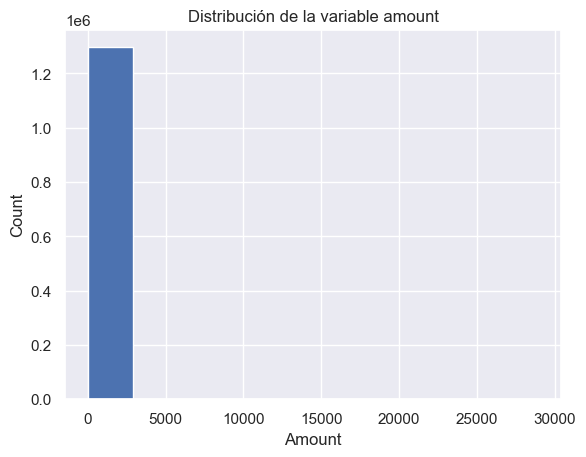

In [10]:
sns.set_theme()

df["amount"].hist()
plt.title("Distribución de la variable amount")
plt.xlabel("Amount")
plt.ylabel("Count")
plt.show()

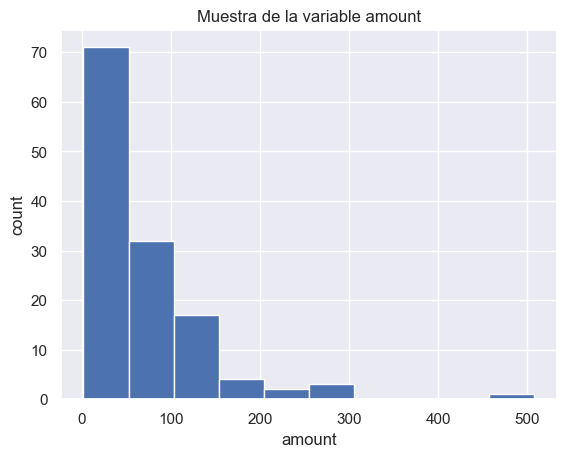

In [11]:
sns.set_theme()

sample= df["amount"].sample(frac=0.0001,random_state=1)
plt.title("Muestra de la variable amount")
plt.ylabel("count")
plt.xlabel("amount")
sample.hist()
plt.show()

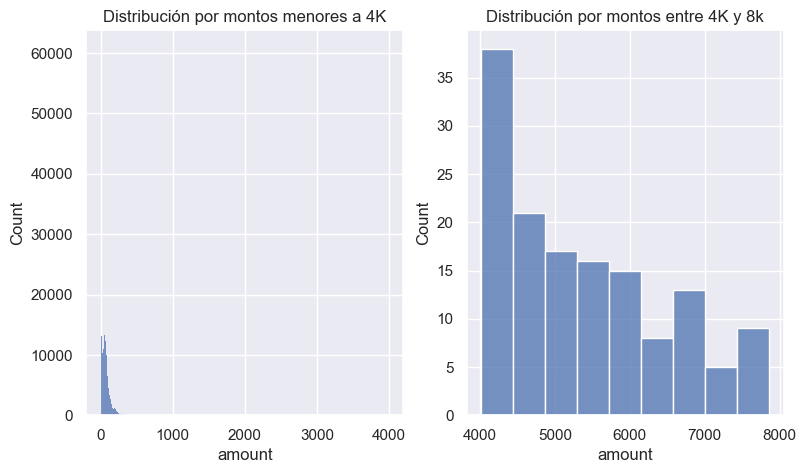

In [12]:
sns.set_theme(style="darkgrid")
fig,ax = plt.subplots(1,2, figsize=(9,5))

sns.histplot(df[df["cat_amount"] == 1]["amount"], ax=ax[0])
ax[0].set_title("Distribución por montos menores a 4K")
sns.histplot(df[df["cat_amount"] == 2]["amount"], ax=ax[1])
ax[1].set_title("Distribución por montos entre 4K y 8k")
plt.show()

In [13]:
round(df["amount"].median())

48

## Observaciones:
### . La característica amount sigue una distribución lognormal sesgada a la derecha
### . El 99.4% de las transacciones tienen montos por menos de 4k dolares
### . Las transacciones tienen generalmente montos bajos
### . El 50% de las transacciones tienen montos por menos de 48 dolares

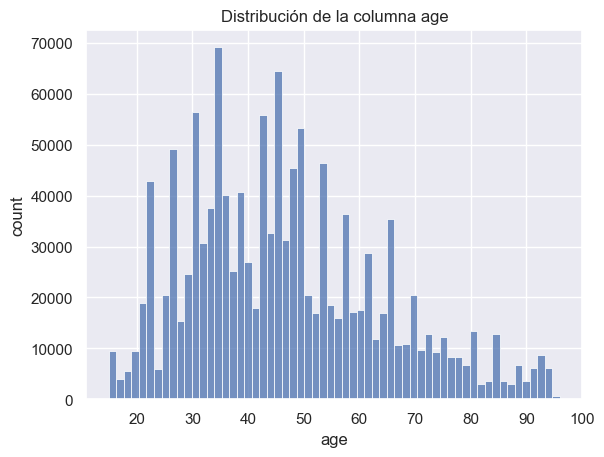

In [14]:
sns.set_theme()

sns.histplot(data=df, x="age", kde=False, bins=60)
plt.title("Distribución de la columna age")
plt.xlabel("age")
plt.ylabel("count")

plt.show()

In [15]:
round(df["age"].describe().reset_index())

,index,age
0,count,1296675.0
1,mean,47.0
2,std,17.0
3,min,15.0
4,25%,33.0
5,50%,45.0
6,75%,58.0
7,max,96.0


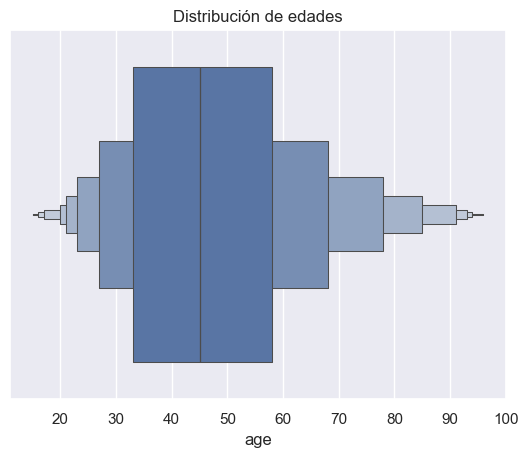

In [16]:
sns.boxenplot(data=df, x="age")
plt.title("Distribución de edades")
plt.show()

## Observaciones:
### . El 68% de las personas estan entre los 30 y 60 años aproximadamente
### . La característica age tiene una distribución lognormal sesgada a la derechas
### . Hay muchas personas adultas y muy pocas mayores y menores de edad
### . En promedio las personas tiene al rededor de 47 años

In [17]:
df_sample = df.sample(n=900, random_state=42)
fig = px.density_mapbox(df_sample, lat="merch_lat",lon="merch_long", radius=10, mapbox_style="open-street-map", title="Distribución los mercados geográficamente con una muestra representativa de 900 transacciones")
fig.update_layout(coloraxis_colorbar=dict(title="concentración"))

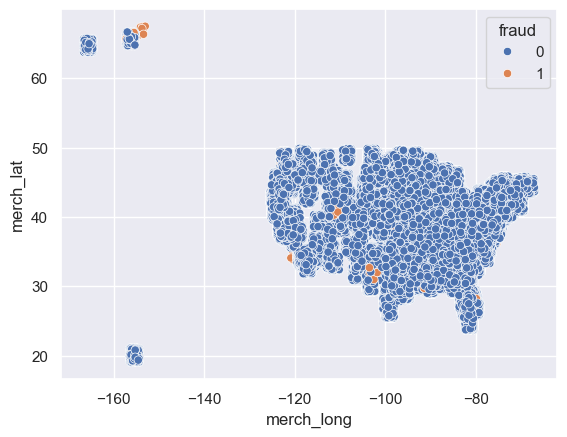

In [18]:
sns.scatterplot(data = df, x="merch_long", y="merch_lat", hue="fraud")
plt.show()

## Observaciones
### . Aunque los mercados estan presentes en todo el país, se concentran mas en el noroeste
### . A simple vista no hay patrones que indiquen una mayor preferencia de mercados

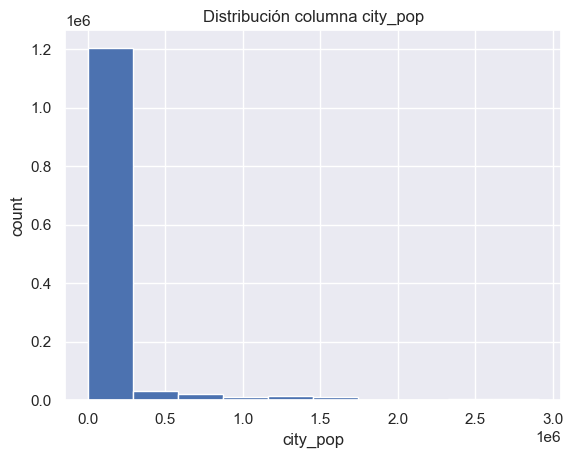

In [19]:
sns.set_theme()
df["city_pop"].hist()
plt.title("Distribución columna city_pop")
plt.xlabel("city_pop")
plt.ylabel("count")
plt.show()

In [20]:
round(df["city_pop"].describe().reset_index())

,index,city_pop
0,count,1296675.0
1,mean,88824.0
2,std,301956.0
3,min,23.0
4,25%,743.0
5,50%,2456.0
6,75%,20328.0
7,max,2906700.0


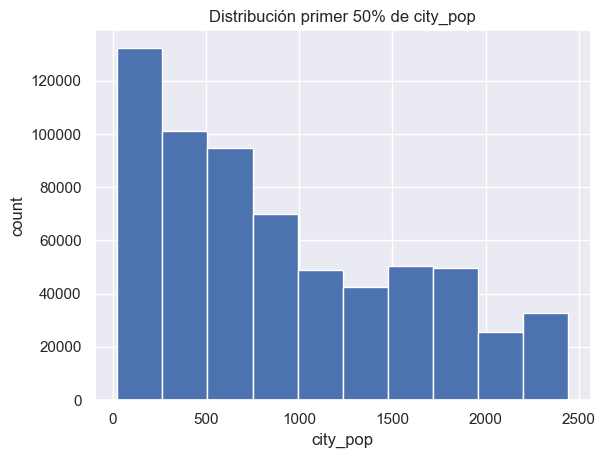

In [21]:
df[df["city_pop"] < 2456]["city_pop"].hist()
plt.title("Distribución primer 50% de city_pop")
plt.xlabel("city_pop")
plt.ylabel("count")
plt.show()

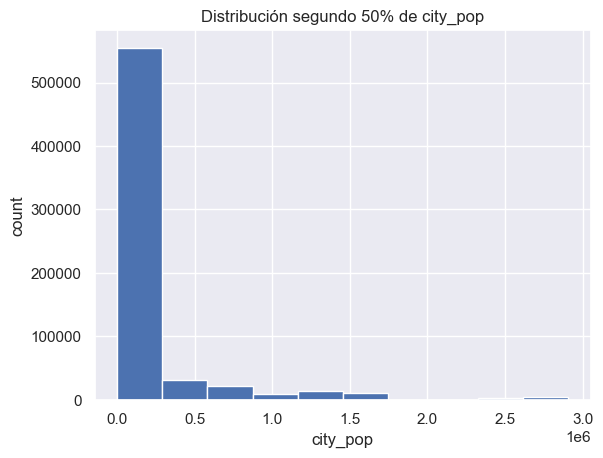

In [22]:
df[df["city_pop"] > 2456]["city_pop"].hist()
plt.title("Distribución segundo 50% de city_pop")
plt.xlabel("city_pop")
plt.ylabel("count")
plt.show()

## Observaciones:
### . A pesar de la variedad, la mayoria de las personas con tarjetas de credito viven en ciudades poco pobladas
### . el 50% de las personas viven en ciudades con menos de 2500 habitantes

In [23]:
print("Porcentaje de transacciones en 2019: ")
print((df["trans_year"].value_counts()[2019]/df.shape[0])*100)
print(" ")
print("Porcentaje de transacciones en 2020: ")
print((df["trans_year"].value_counts()[2020]/df.shape[0])*100)

Porcentaje de transacciones en 2019: 
71.32473441687392
 
Porcentaje de transacciones en 2020: 
28.675265583126077


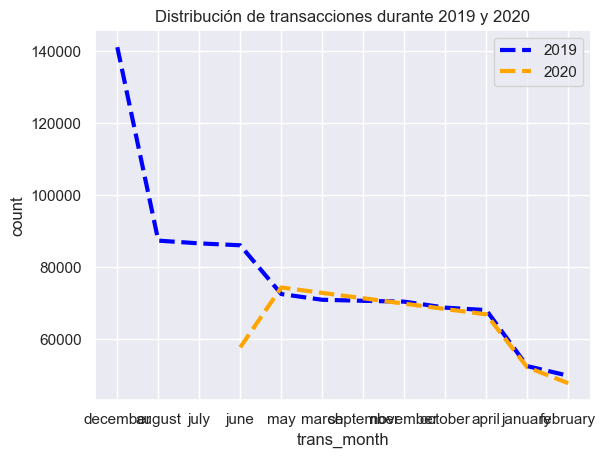

In [24]:
f = df[df["trans_year"] == 2019]["trans_month"].value_counts()
f2 = df[df["trans_year"] == 2020]["trans_month"].value_counts()

sns.lineplot(f, label="2019", linestyle="--", linewidth=3, color="blue")
sns.lineplot(f2, label="2020", linestyle="--", linewidth=3, color="orange")

plt.title("Distribución de transacciones durante 2019 y 2020")
plt.show()

In [25]:
print("Porcentaje de transacciones por mes en 2019")
(f/f.sum())*100

Porcentaje de transacciones por mes en 2019


trans_month
december     15.252203
august        9.445748
july          9.363248
june          9.305725
may           7.842569
march         7.670325
september     7.639293
november      7.614316
october       7.434503
april         7.360977
january       5.679299
february      5.391793
Name: count, dtype: float64

In [26]:
print("Porcentaje de transacciones por mes en 2020")
(f2/f2.sum())*100

Porcentaje de transacciones por mes en 2020


trans_month
may         19.994083
march       19.592550
april       17.990184
june        15.530693
january     14.039400
february    12.853089
Name: count, dtype: float64

## Observaciones:
### . El 71% delas transacciones se realizaron en 2019 frente a un 29% en 2020
### . Se cuenta solo con el primer semestre de 2020
### . El 15% de las transacciones realizadas en 2019 fueron en Diciembre
### . Comparando 2019 y 2020, se puede ver que se continua la tendencia excepto en Junio de 2020 donde el numero de transacciones se redujo comparado con 2019

## Variables categóricas

In [27]:
print("Cantidad de personas por grupos etarios")
df["age_groups"].value_counts().reset_index()

Cantidad de personas por grupos etarios


,age_groups,count
0,Adult,991947
1,Elder,291298
2,Minor,13430


In [28]:
print("Porcentaje de personas por grupos etarios")
((df["age_groups"].value_counts()/df.shape[0])*100).reset_index()

Porcentaje de personas por grupos etarios


,age_groups,count
0,Adult,76.499277
1,Elder,22.464997
2,Minor,1.035726


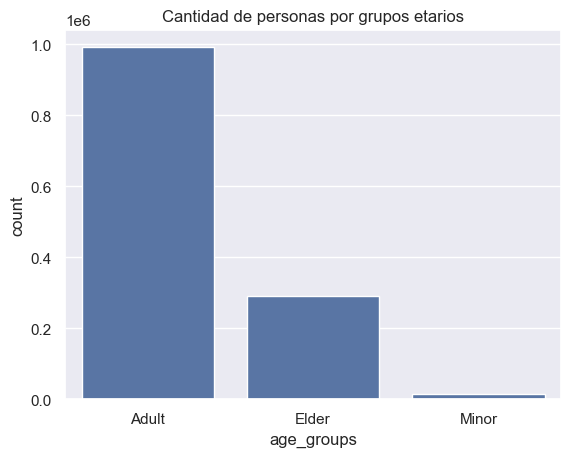

In [29]:
sns.countplot(data=df, x="age_groups")
plt.title("Cantidad de personas por grupos etarios")
plt.show()

In [30]:
print("Moda de grupos etarios")
df["age_groups"].mode()[0]

Moda de grupos etarios


'Adult'

## Observaciones:
### . El 76% de las personas son adultos jovenes y mayores con un rango entre 30 y 60 años
### . Hay presencia casi nula de personas menores de edad

In [6]:
df["unique_person"] = df["name"] + " / " + df["age"].astype(str)

In [32]:
n = df["unique_person"].value_counts()

In [33]:
count = []
count.append(len(n[n < 1000]))
count.append(len(n[(n >= 1000) & (n < 2000)]))
count.append(len(n[(n >= 2000)  & (n < 3000)]))
count.append(len(n[(n >= 3000) & (n < 4000)]))
count.append(len(n[n > 4000]))
print("Valor minimo: ", n.min())
print("Valor maximo: ", n.max())

Valor minimo:  7
Valor maximo:  3123


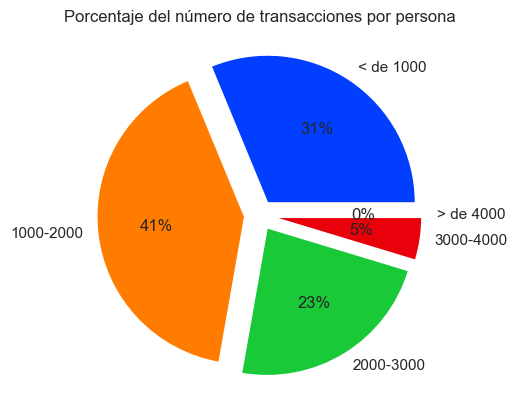

In [34]:
sns.set_theme(style="darkgrid")
colors = sns.color_palette("bright")[0:5]
labels = ["< de 1000", "1000-2000", "2000-3000","3000-4000","> de 4000"]
explode = [0.1,0.1,0.1,0.1,0.1]
plt.pie(count, colors=colors, labels=labels, autopct="%.0f%%", startangle=0, explode=explode)
plt.title("Porcentaje del número de transacciones por persona")
plt.show()

In [35]:
print(" Top 10 de personas con mas transacciones realizadas")
n[0:10].reset_index()

 Top 10 de personas con mas transacciones realizadas


,unique_person,count
0,Barbara_Taylor / 25,3123
1,Monica_Cohen / 37,3123
2,Jessica_Perez / 33,3119
3,Ana_Howell / 36,3117
4,Keith_Sanders / 21,3113
5,Christine_Harris / 22,3112
6,Tammy_Ayers / 32,3110
7,Mark_Wood / 23,3107
8,Allison_Allen / 27,3106
9,Rebecca_Erickson / 37,3101


## Observaciones:
### . De los 983 usuarios el 41% realizo entre 1000 y 2000 transacciones y el 31% menos de 1000, siendo los porcentajes mas altos
### . La persona con mas transacciones realizadas fue Scott_Martín con 4618
### . Hay variedad de gustos, viniendo desde personas que solo realizaron 7 transacciones hasta gente con 4618

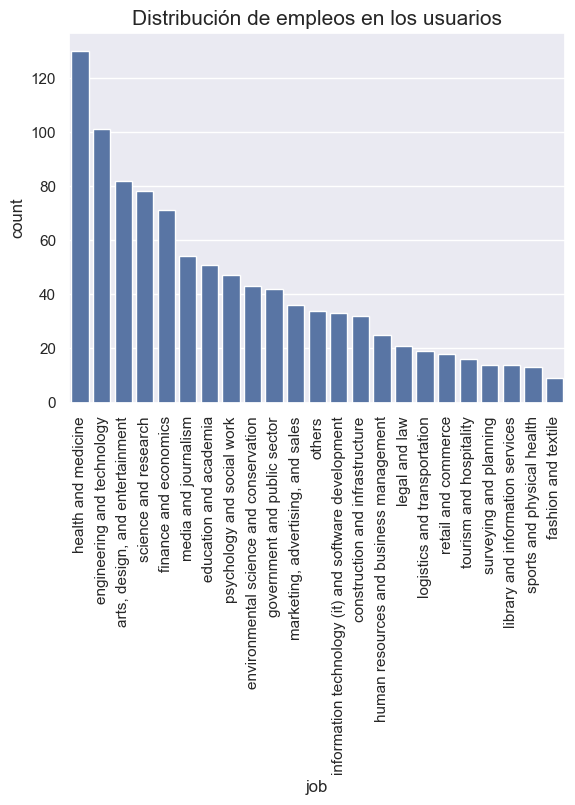

In [36]:
j = df[df["unique_person"].duplicated() == False]["job"].value_counts()
sns.barplot(x=j.keys(), y=(df[df["unique_person"].duplicated() == False]["job"].value_counts()))
plt.xticks(rotation=90)
plt.title("Distribución de empleos en los usuarios", fontsize=15)
plt.show()

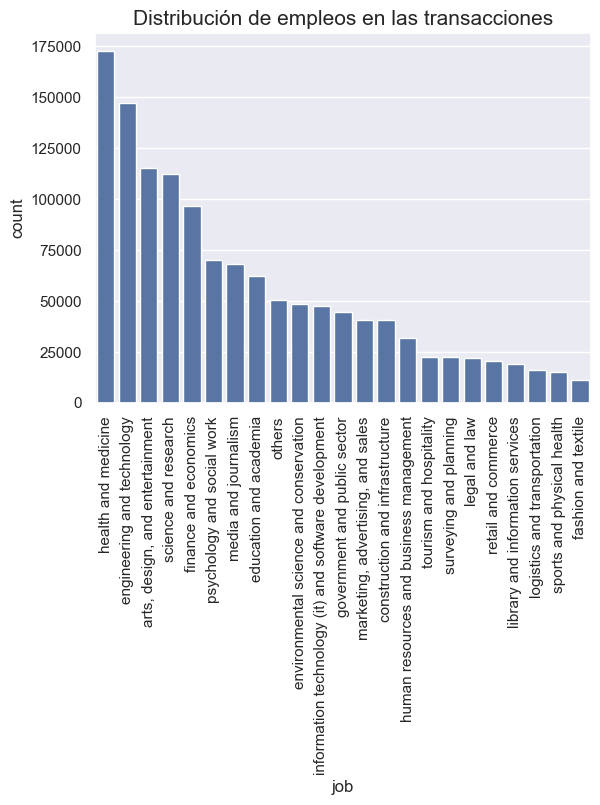

In [37]:
j2 = df["job"].value_counts()
sns.barplot(x=j2.keys(), y=(df["job"].value_counts()))
plt.xticks(rotation=90)
plt.title("Distribución de empleos en las transacciones", fontsize=15)
plt.show()

In [38]:
print("Distribución de empleos en las personas")
print(" ")
print(j)
print(" ")
print("Distribución de enpleos por transacciones")
print(j2)

Distribución de empleos en las personas
 
job
health and medicine                                     130
engineering and technology                              101
arts, design, and entertainment                          82
science and research                                     78
finance and economics                                    71
media and journalism                                     54
education and academia                                   51
psychology and social work                               47
environmental science and conservation                   43
government and public sector                             42
marketing, advertising, and sales                        36
others                                                   34
information technology (it) and software development     33
construction and infrastructure                          32
human resources and business management                  25
legal and law                                         

## Observaciones:
### . El 13% delas personas trabajan en el sector de la salúd, siendo este el sector mas grande
### . El 13 % de las transacciones las realizo este grupo, por lo que es el que mas transacciones realiza
### . Los sectores con mas presencia son el de la Salúd, Ingenieria y Arte

In [39]:
print("Moda de la columna Type_purcharse: ", df["type_purcharse"].mode())

Moda de la columna Type_purcharse:  0    gas_transport
Name: type_purcharse, dtype: object


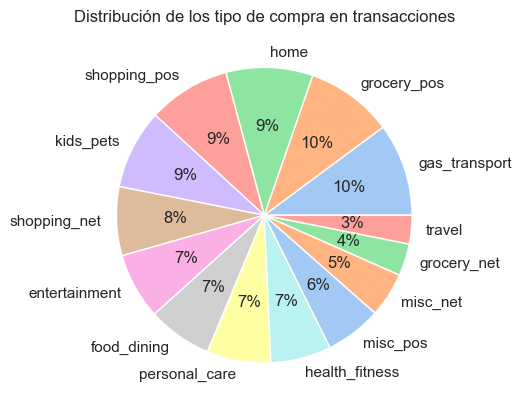

In [40]:
purcharse = df["type_purcharse"].value_counts()
sns.set_theme()
colors = sns.color_palette("pastel")[0:14]

plt.pie(purcharse, labels=purcharse.keys(), colors=colors, autopct="%.0f%%", startangle=0)
plt.title("Distribución de los tipo de compra en transacciones", fontsize=12)
plt.show()

In [41]:
print(purcharse)

type_purcharse
gas_transport     131659
grocery_pos       123638
home              123115
shopping_pos      116672
kids_pets         113035
shopping_net       97543
entertainment      94014
food_dining        91461
personal_care      90758
health_fitness     85879
misc_pos           79655
misc_net           63287
grocery_net        45452
travel             40507
Name: count, dtype: int64


## Observaciones:
### . El 20% de las transacciones fueron con proposito de transporte y golosinas
### . Eltipo de compra que masse repite en las transacciones es transporte con 131659 transacciones
### . La categoria mas baja es la de viajes con un 3%

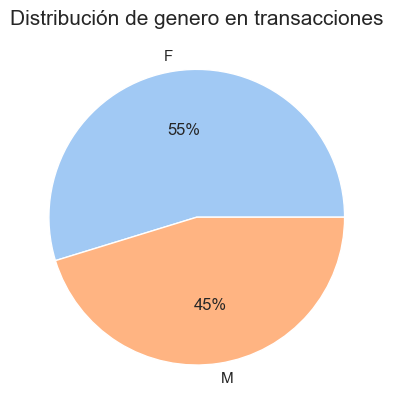

In [42]:
g = df["gender"].value_counts()
colors = sns.color_palette("pastel")[0:2]
plt.pie(g, colors=colors, labels=g.keys(), autopct="%.0f%%", startangle=0)
plt.title("Distribución de genero en transacciones", fontsize=15)
plt.show()

In [43]:
g.reset_index()

,gender,count
0,F,709863
1,M,586812


## Observaciones:
### . Hay mas mujeres que hombres con una diferencia del 105
### . El 55% de las personas son mujeres frente a un 45% de los hombres

In [44]:
print("Moda de mercados: ", df["merchant"].mode())
print("Porcentaje de la moda: ", ((df["merchant"].value_counts()/df.shape[0])*100)[0])
print("Cantidad de mercados prsentes en transacciones: ", len(df["merchant"].value_counts()))

Moda de mercados:  0    Kilback LLC
Name: merchant, dtype: object
Porcentaje de la moda:  0.33956079973779085
Cantidad de mercados prsentes en transacciones:  693


In [45]:
((df["merchant"].value_counts()/df.shape[0]*100)).head(20)

merchant
Kilback LLC                       0.339561
Cormier LLC                       0.281412
Schumm PLC                        0.280255
Kuhn LLC                          0.270692
Boyer PLC                         0.269381
Dickinson Ltd                     0.264831
Cummerata-Jones                   0.211001
Kutch LLC                         0.210847
Olson, Becker and Koch            0.209999
Stroman, Hudson and Erdman        0.209844
Rodriguez Group                   0.209459
Erdman-Kertzmann                  0.208610
Jenkins, Hauck and Friesen        0.208610
Kling Inc                         0.207222
Connelly, Reichert and Fritsch    0.206991
Friesen-Stamm                     0.206682
Prohaska-Murray                   0.206605
Huels-Hahn                        0.206528
Berge LLC                         0.206451
Bartoletti-Wunsch                 0.206374
Name: count, dtype: float64

## Observaciones:
### . Hay una gran variedad de mercados en el dataframe (693) dispersos por toda USA
### . El mercado que mas se repite es el de Kilback LLC con un 3% de los mercados totales

## Análisis bivariado y multivariado

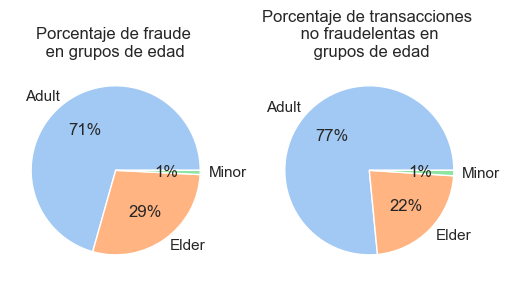

In [46]:
age_fraud = df[df["fraud"] == 1]["age_groups"].value_counts()
age = df[df["fraud"] == 0]["age_groups"].value_counts()

sns.set_theme(style="dark")
colors = sns.color_palette("pastel")[0:3]
fig,ax = plt.subplots(1,2,figsize=(6,6))

ax[0].pie(age_fraud, colors=colors, labels=age_fraud.keys(), autopct="%.0f%%", startangle=0)
ax[0].set_title("Porcentaje de fraude \n en grupos de edad ")

ax[1].pie(age, colors=colors, labels=age.keys(), autopct="%.0f%%", startangle=0)
ax[1].set_title("Porcentaje de transacciones \n no fraudelentas en \n grupos de edad")

plt.show()

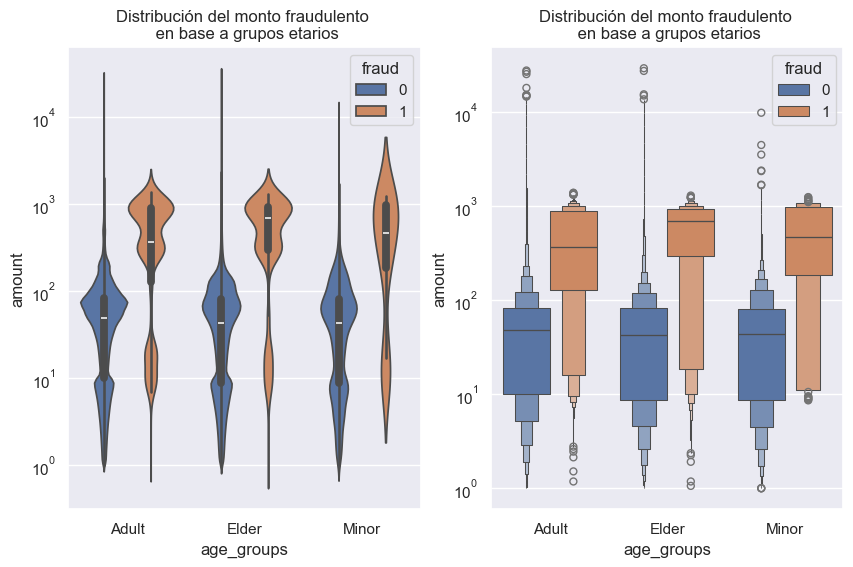

In [47]:
fraud = df[df["fraud"] == 1]

sns.set_theme(style="darkgrid")
fig,ax= plt.subplots(1,2, figsize=(10,6))
                     
sns.violinplot(data=df, x="age_groups", y="amount", hue="fraud", log_scale=True, ax=ax[0])
ax[0].set_title("Distribución del monto fraudulento \n en base a grupos etarios")

sns.boxenplot(data=df, x="age_groups", y="amount", hue="fraud", log_scale=True, ax=ax[1])
ax[1].set_title("Distribución del monto fraudulento \n en base a grupos etarios")

plt.show()

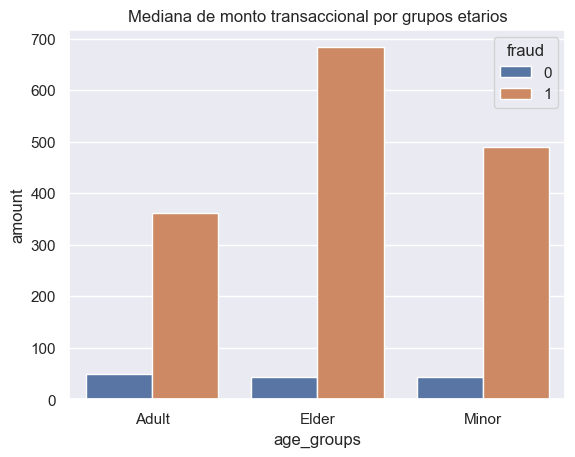

In [48]:
sns.set_theme(style="darkgrid")

sns.barplot(data=df , x="age_groups", y="amount", hue="fraud", estimator="median", errorbar=None)
plt.title("Mediana de monto transaccional por grupos etarios")
plt.show()

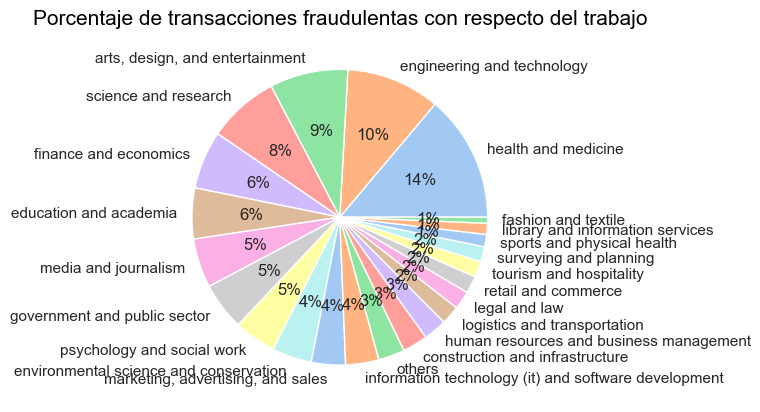

In [49]:
fraud = df[df["fraud"] == 1]["job"].value_counts()
colors = sns.color_palette("pastel")[0:20]

sns.set_theme(style="darkgrid")
plt.pie(fraud, labels=fraud.keys(), colors=colors, autopct="%.0f%%", startangle=0)
plt.title("Porcentaje de transacciones fraudulentas con respecto del trabajo", fontsize=15, color="black")
plt.show()

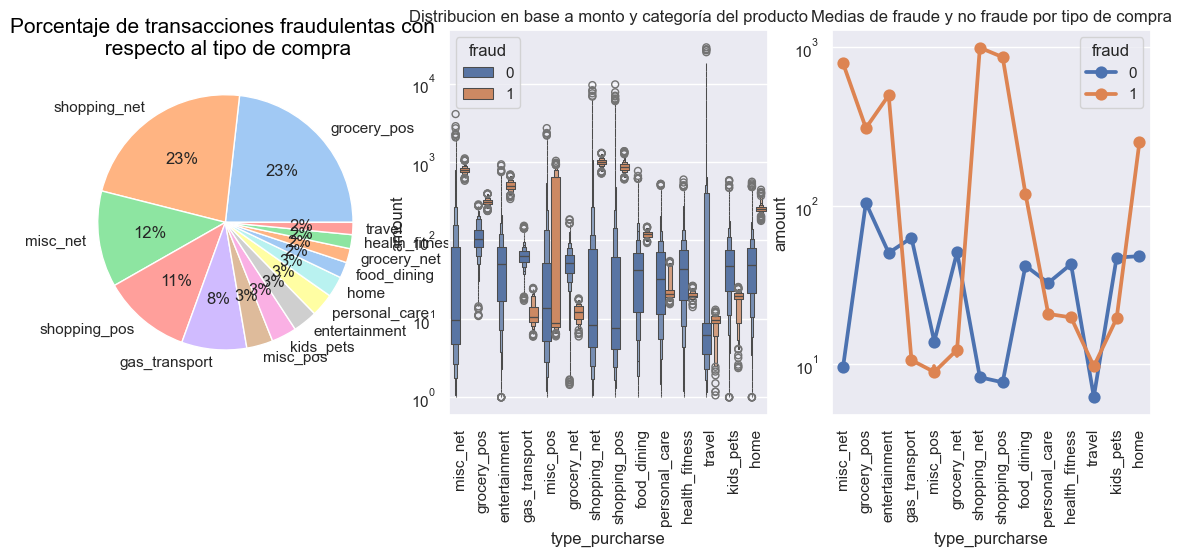

In [51]:
purcharse = df[df["fraud"] == 1]["type_purcharse"].value_counts()
colors = sns.color_palette("pastel")[0:20]
fig,ax= plt.subplots(1,3, figsize=(14,5))

sns.set_theme(style="darkgrid")

ax[0].pie(purcharse, labels=purcharse.keys(), colors=colors, autopct="%.0f%%", startangle=0)
ax[0].set_title("Porcentaje de transacciones fraudulentas con \n respecto al tipo de compra", fontsize=15, color="black")

sns.boxenplot(data=df, x="type_purcharse", y ="amount", hue="fraud", log_scale=True, ax=ax[1])
ax[1].set_title("Distribucion en base a monto y categoría del producto")
ax[1].tick_params("x", rotation=90)

sns.pointplot(data=df, x="type_purcharse", y="amount", estimator="median", hue="fraud", log_scale=True, ax=ax[2])
ax[2].set_title("Medias de fraude y no fraude por tipo de compra")
ax[2].tick_params("x", rotation=90)

plt.show()

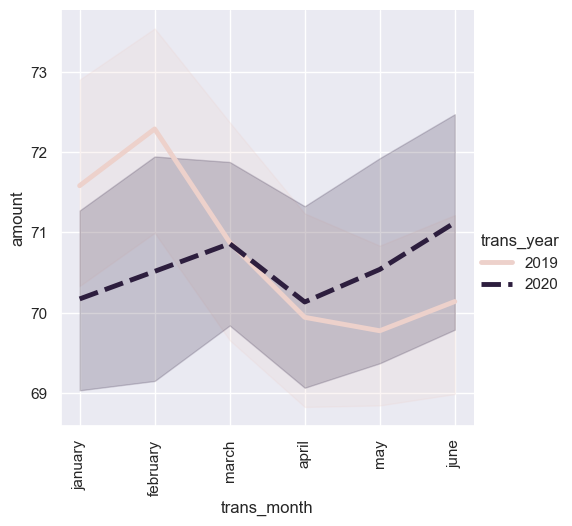

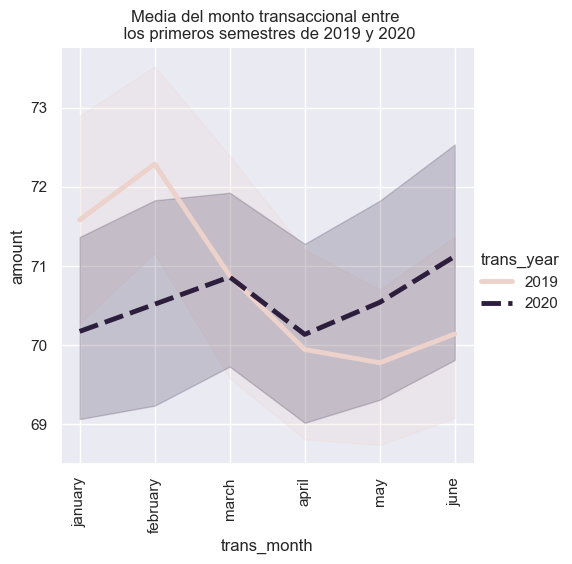

In [53]:
month = ["january", "february", "march", "april", "may", "june"]
date = df[df["trans_month"].isin(month)]

sns.relplot(data=df[df["trans_month"].isin(month)], x="trans_month", y="amount", hue="trans_year", style="trans_year", kind="line", linewidth=3.5, estimator="mean")
plt.xticks(rotation=90)
plt.title("Media del monto transaccional entre \n los primeros semestres de 2019 y 2020")
plt.show()


In [54]:
df["time"] = df["trans_date"].dt.strftime("%Y-%m")

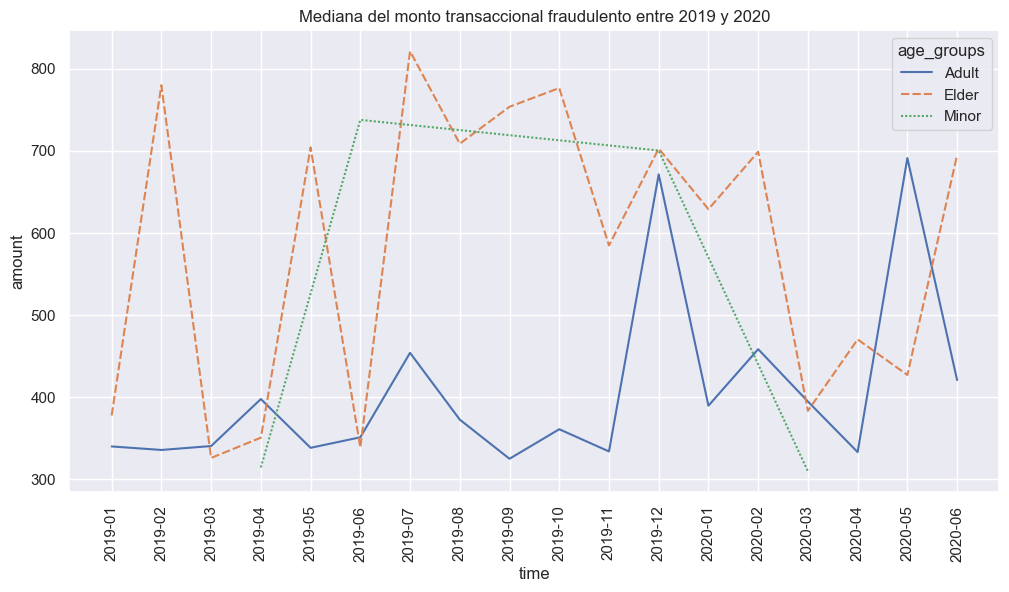

In [55]:
fig,ax = plt.subplots(figsize=(12,6))

sns.lineplot(data=df.query("fraud == 1"), x="time", y="amount", estimator="median", hue="age_groups", style="age_groups", errorbar=None)
#ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.title("Mediana del monto transaccional fraudulento entre 2019 y 2020")
plt.xticks(rotation=90)
plt.show()

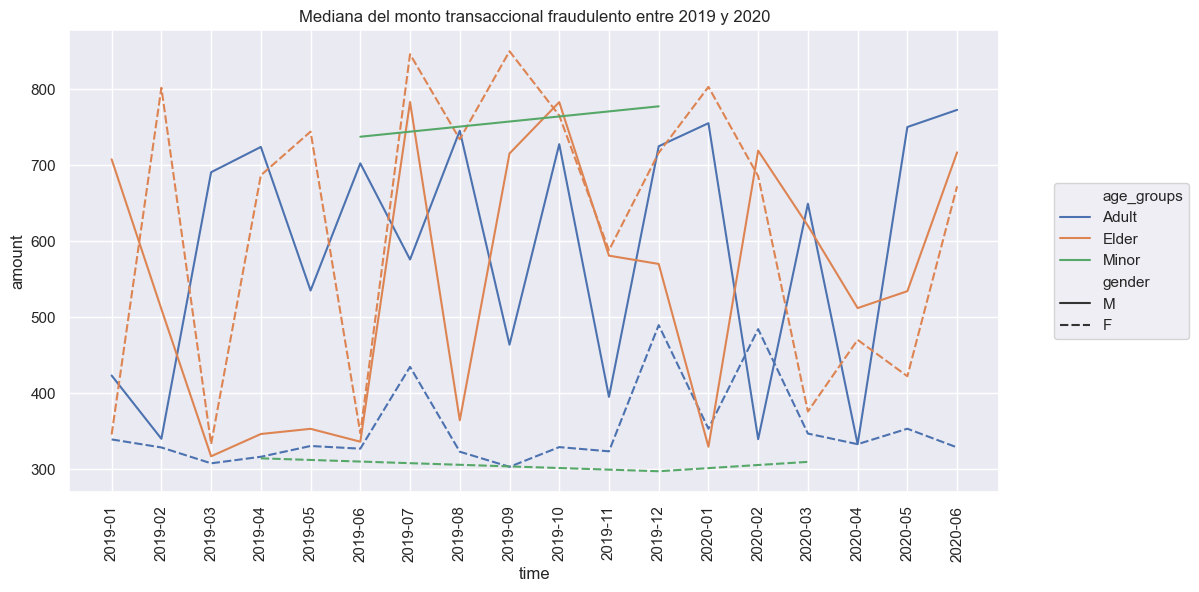

In [56]:
fig,ax = plt.subplots(figsize=(12,6))

g = sns.lineplot(data=df.query("fraud == 1"), x="time", y="amount", estimator="median", hue="age_groups", style="gender", errorbar=None)
#ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.title("Mediana del monto transaccional fraudulento entre 2019 y 2020")
plt.xticks(rotation=90)

ax.legend(bbox_to_anchor=(1.05, 0.5), loc='center left')
plt.show()

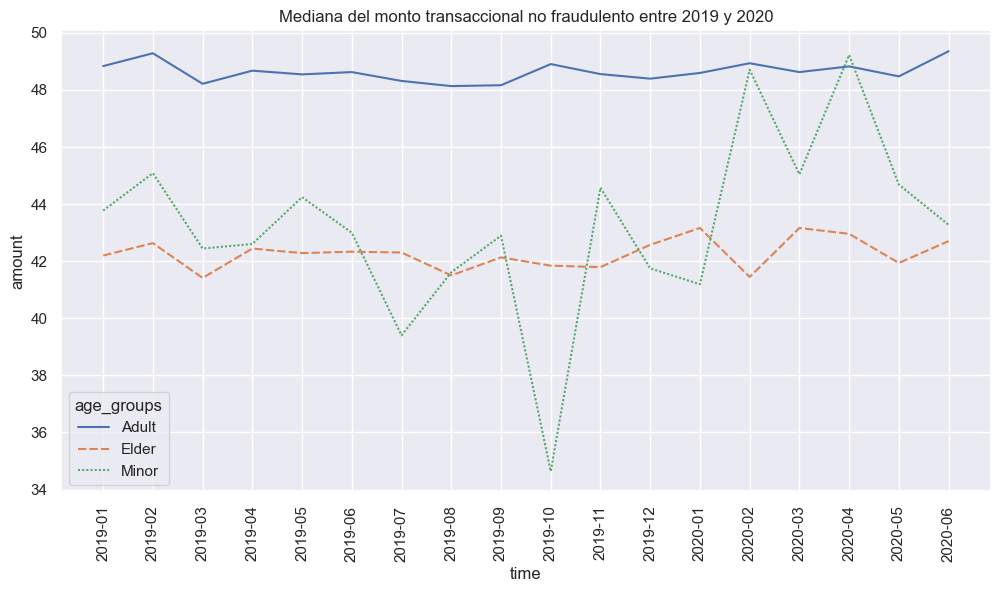

In [57]:
fig,ax = plt.subplots(figsize=(12,6))

sns.lineplot(data=df.query("fraud == 0"), x="time", y="amount", estimator="median", hue="age_groups", style="age_groups", errorbar=None)
plt.title("Mediana del monto transaccional no fraudulento entre 2019 y 2020")
plt.xticks(rotation=90)
plt.show()

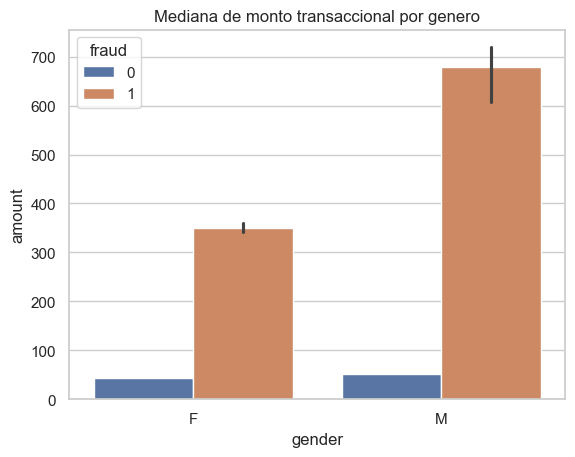

In [58]:
sns.set_theme(style="whitegrid")

sns.barplot(data=df, x="gender", y="amount", estimator="median", hue="fraud")
plt.title("Mediana de monto transaccional por genero")
plt.show()

In [59]:
df[df["fraud"] == 1]["gender"].value_counts().reset_index()

,gender,count
0,M,3771
1,F,3735


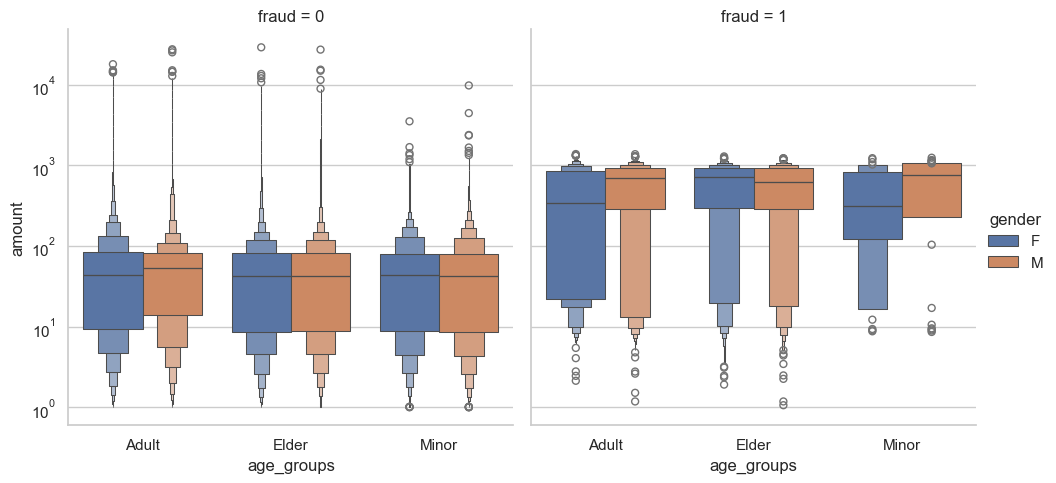

In [60]:
sns.catplot(data=df, x="age_groups", y="amount", hue="gender", col="fraud", log_scale=True, kind="boxen")
plt.show()

In [30]:
tasa = pd.crosstab(df["state"], df["fraud"])
tasa["%rate%"] = (tasa[1]/tasa[0]) *100
tasa["%rate%"] = tasa["%rate%"].replace(np.inf,100)

In [33]:
print("Estado con mayor tasa de fraude: ", tasa["%rate%"].max())
print("Estado con menor tasa de fraude: ", tasa["%rate%"].min())
print("Media de tasa de fraude por estado: ", tasa["%rate%"].mean())

Estado con mayor tasa de fraude:  100.0
Estado con menor tasa de fraude:  0.19877123238164077
Media de tasa de fraude por estado:  2.580833068618


In [49]:
tasa_edad = pd.pivot_table(df, index="fraud", columns="state", values="age", aggfunc="mean")
tasa_edad.iloc[0] = tasa_edad.iloc[0].replace(np.NaN, 0)

In [50]:
print("Promedio de edades fraudulentas: ", tasa_edad.iloc[1].mean())
print("Promedio de edades no fraudulentas: ", tasa_edad.iloc[0].mean())

Promedio de edades fraudulentas:  47.80837466463929
Promedio de edades no fraudulentas:  45.4699596541567


# Exportando Info

In [70]:
df.to_csv("FraudTrainAnalyzed.csv")

# Muestra Para App

In [4]:
df = pd.read_csv("FraudTrainAnalyzed.csv")

In [7]:
muestra = pd.concat([df[df["fraud"] == 1].sample(20), df[df["fraud"] == 0].sample(80)], axis=0)
muestra

,Unnamed: 0,trans_num,trans_date,cc_num,merchant,type_purcharse,amount,gender,city,state,...,merch_long,fraud,trans_year,trans_month,age,age_groups,name,cat_amount,unique_person,time
518370,518370,0325b4bce2b98975c7f32c6bc6fde537,2019-08-11,4189814094741,"Streich, Dietrich and Barton",shopping_net,888.06,M,Ragland,AL,...,-85.354081,1,2019,august,22,Adult,Jason_Farmer,1,Jason_Farmer / 22,2019-08
1268441,1268441,498a0536efb0cbdb32150da8bc7be0e5,2020-06-10,3549202406645667,"Daugherty, Pouros and Beahan",shopping_pos,948.84,M,Scarborough,ME,...,-69.416392,1,2020,june,87,Elder,Larry_Williams,1,Larry_Williams / 87,2020-06
1067409,1067409,4b2d3b13ae2a545002c0584f9d758ef4,2020-03-19,2231186809828225,Bauch-Raynor,grocery_pos,266.42,F,Vienna,GA,...,-83.738057,1,2020,march,63,Elder,Katherine_Pennington,1,Katherine_Pennington / 63,2020-03
681581,681581,72ee4787b669ac5dd56190b1458c4f1d,2019-10-18,4561546772499,Murray-Smitham,grocery_pos,305.65,M,Moriarty,NM,...,-105.114688,1,2019,october,32,Adult,Daniel_Briggs,1,Daniel_Briggs / 32,2019-10
893206,893206,b0e621fb6ef2c21cf47f831baf82cebd,2019-12-24,6011581063717667,Pouros-Haag,shopping_pos,737.77,M,Brashear,MO,...,-91.672178,1,2019,december,50,Adult,Jerry_Perkins,1,Jerry_Perkins / 50,2019-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
603131,603131,7389b88a051345ad0e6b795cb5a6f0b6,2019-09-13,213178850083780,"Yost, Schamberger and Windler",kids_pets,45.00,M,Athena,OR,...,-117.800384,0,2019,september,44,Adult,Shawn_King,1,Shawn_King / 44,2019-09
359634,359634,3762b8eb10320b76625b9bffd5e865b3,2019-06-16,3500969075198072,Kris-Padberg,shopping_pos,157.06,M,Tekoa,WA,...,-117.898378,0,2019,june,21,Adult,Kenneth_Sanchez,1,Kenneth_Sanchez / 21,2019-06
713861,713861,006fcaff425d34c0b6891503a870c8fe,2019-11-01,344709867813900,"Goldner, Kovacek and Abbott",grocery_pos,218.30,F,Sebring,FL,...,-81.692791,0,2019,november,34,Adult,Joanna_Hudson,1,Joanna_Hudson / 34,2019-11
1119779,1119779,b40f19ce10fd35432dd77131bfeb66b8,2020-04-11,4653879239169997,Zboncak Ltd,food_dining,1.20,F,Smiths Grove,KY,...,-87.100508,0,2020,april,21,Adult,Monica_Tucker,1,Monica_Tucker / 21,2020-04


In [8]:
df.drop(labels=["Unnamed: 0"], axis=1, inplace=True)

In [9]:
df.reset_index(inplace=True)
df.pop("index")
df.head(2)

,trans_num,trans_date,cc_num,merchant,type_purcharse,amount,gender,city,state,city_pop,...,merch_long,fraud,trans_year,trans_month,age,age_groups,name,cat_amount,unique_person,time
0,0b242abb623afc578575680df30655b9,2019-01-01,2703186189652095,"Rippin, Kub and Mann",misc_net,4.97,F,Moravian Falls,NC,3495,...,-82.048315,0,2019,january,32,Adult,Jennifer_Banks,1,Jennifer_Banks / 32,2019-01
1,1f76529f8574734946361c461b024d99,2019-01-01,630423337322,"Heller, Gutmann and Zieme",grocery_pos,107.23,F,Orient,WA,149,...,-118.186462,0,2019,january,42,Adult,Stephanie_Gill,1,Stephanie_Gill / 42,2019-01


In [24]:
df.to_csv("AppData.csv")